#Phase 1: Colab Environment Setup
Mount Google Drive (Python)

**Purpose:** Mount Google Drive so all project files under `prion_rnaseq_meta_analysis/` are accessible at `/content/drive/MyDrive/`.

**Inputs:** Google account with the project folder in Drive.

**Outputs:** Drive mounted at `/content/drive`.

**Key decisions:** Run this cell first every session; re-mounting is safe.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


##Enable R Magic (Python)

**Purpose:** Load the `rpy2.ipython` extension so subsequent cells can use the `%%R` magic to run R code inside this Python notebook.

**Inputs:** None.

**Outputs:** R magic enabled for all subsequent `%%R` cells.

**Key decisions:** Must be run before any `%%R` cell; safe to re-run.

In [2]:
%load_ext rpy2.ipython

##Install Required Packages (R)

**Purpose:** Install all R packages needed for cell-type deconvolution: biomaRt for Ensembl ID mapping, DESeq2/tximeta for count data access, and ggplot2/patchwork for figures.

**Inputs:** Internet connection (first run only).

**Outputs:** All packages installed and available for loading in Section 0.

**Key decisions:** Run this cell only once per session — it takes ~5 minutes. `ask = FALSE, update = FALSE` prevents interactive prompts in Colab.

In [3]:
%%R
if (!requireNamespace("BiocManager", quietly = TRUE))
  install.packages("BiocManager")

BiocManager::install(c("tximeta", "DESeq2", "SummarizedExperiment",
                       "biomaRt"), ask = FALSE, update = FALSE)

install.packages(c("ggplot2", "ggrepel", "patchwork", "dplyr", "tidyr",
                   "tibble", "readr", "stringr", "scales", "RColorBrewer",
                   "viridis"), repos = "https://cloud.r-project.org")

cat("All packages installed.\n")

All packages installed.


Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)
trying URL 'https://cran.rstudio.com/src/contrib/BiocManager_1.30.27.tar.gz'
Content type 'application/x-gzip' length 752490 bytes (734 KB)
downloaded 734 KB


The downloaded source packages are in
	‘/tmp/RtmpzfLp0B/downloaded_packages’
'getOption("repos")' replaces Bioconductor standard repositories, see
'help("repositories", package = "BiocManager")' for details.
Replacement repositories:
    CRAN: https://cran.rstudio.com
Bioconductor version 3.23 (BiocManager 1.30.27), R 4.6.0 (2026-04-24)
Installing package(s) 'BiocVersion', 'tximeta', 'DESeq2',
  'SummarizedExperiment', 'biomaRt'
also installing the dependencies ‘cigarillo’, ‘RCurl’, ‘formatR’, ‘png’, ‘XML’, ‘GenomicAlignments’, ‘restfulr’, ‘lazyeval’, ‘bitops’, ‘Rhtslib’, ‘lambda.r’, ‘futile.options’, ‘RSQLite’, ‘KEGGREST’, ‘XVector’, ‘rtracklayer’, ‘rjson’, ‘UCSC.utils’, ‘GenomeInfoDb’, ‘BiocIO’, ‘AnnotationFilter’, ‘Rsamtools’, ‘ProtGenerics’, ‘f

##Section 0 — Libraries, Configuration & Helper Functions

**Purpose:** Load all R packages, define paths, configure the `save_fig()` helper and `theme_pub` ggplot2 theme, and define the MCPS gene list. Sets up the working environment for all downstream sections.

**Inputs:** None (constants defined inline).

**Outputs:** `BASE_DIR`, `STREAM1_DIR`, `OUT_DIR`, `FIG_DIR`, `MCPS_GENES`, `theme_pub`, `save_fig()` available in R.

**Key decisions:** `FIG_DIR` is created if it does not exist. All figures are saved as PNG (300 dpi) to `../results/figures/`.

In [4]:
%%R
# =============================================================================
# SECTION 0: LIBRARIES, CONFIGURATION & HELPER FUNCTIONS
# =============================================================================

suppressPackageStartupMessages({
  library(dplyr)
  library(tidyr)
  library(tibble)
  library(readr)
  library(stringr)
  library(ggplot2)
  library(ggrepel)
  library(patchwork)
  library(scales)
  library(RColorBrewer)
  library(viridis)
  library(biomaRt)
  library(SummarizedExperiment)
})

# ---------------------------------------------------------------------------
# 0.1  Paths (Restored standard project paths + Deconvolution specific)
# ---------------------------------------------------------------------------
BASE_DIR    <- "/content/drive/MyDrive/prion_rnaseq_meta_analysis"

# Standard pipeline directories (kept for consistency and cross-referencing)
STREAM1_DIR <- file.path(BASE_DIR, "results", "stream1")
STREAM2_DIR <- file.path(BASE_DIR, "results", "stream2")
STREAM3_DIR <- file.path(BASE_DIR, "results", "stream3")
MCPS_DIR    <- file.path(BASE_DIR, "results", "stream1")

# Dedicated output folders for THIS specific deconvolution analysis
OUT_DIR     <- file.path(BASE_DIR, "results", "deconvolution")
FIG_DIR     <- file.path(BASE_DIR, "reports", "figures", "deconvolution")

for (d in c(OUT_DIR, FIG_DIR)) {
  dir.create(d, recursive = TRUE, showWarnings = FALSE)
}

# ---------------------------------------------------------------------------
# 0.2  Publication theme
# ---------------------------------------------------------------------------
theme_pub <- theme_bw(base_size = 11) +
  theme(
    panel.grid.minor  = element_blank(),
    strip.background  = element_rect(fill = "grey92", colour = NA),
    legend.key.size   = unit(0.4, "cm"),
    plot.title        = element_text(face = "bold", size = 11),
    axis.title        = element_text(size = 10),
    axis.text         = element_text(size = 9)
  )

# ---------------------------------------------------------------------------
# 0.3  save_fig() helper (Q1 Standards: Cairo PDF + 600 DPI)
# ---------------------------------------------------------------------------
save_fig <- function(p, name, w = 7, h = 5) {
  pdf_path <- file.path(FIG_DIR, paste0(name, ".pdf"))
  png_path <- file.path(FIG_DIR, paste0(name, ".png"))
  tryCatch({
    ggsave(pdf_path, plot = p, width = w, height = h, device = cairo_pdf)
    ggsave(png_path, plot = p, width = w, height = h, dpi = 600, type = "cairo")
    cat(sprintf("  Saved (High-Res): %s.pdf + .png\n", name))
  }, error = function(e) {
    warning(sprintf("save_fig failed for '%s': %s", name, conditionMessage(e)))
  })
}

# ---------------------------------------------------------------------------
# 0.4  MCPS gene list
# ---------------------------------------------------------------------------
MCPS_GENES <- c("Slc15a4", "Igsf6", "Fcgr4", "Parp14", "Iigp1", "Il1a")

cat("Section 0 complete.\n")
cat(sprintf("  Output dir: %s\n", OUT_DIR))
cat(sprintf("  Figures dir: %s\n", FIG_DIR))

Section 0 complete.
  Output dir: /content/drive/MyDrive/prion_rnaseq_meta_analysis/results/deconvolution
  Figures dir: /content/drive/MyDrive/prion_rnaseq_meta_analysis/reports/figures/deconvolution


##Section 1 — Cell-Type Marker Gene Definitions

**Purpose:** Define the marker gene lists for 8 CNS cell types used to compute cell-type enrichment scores: Microglia, A1 Astrocytes, A2 Astrocytes, Pan-Astrocytes, Neurons, Oligodendrocytes, OPCs, and Endothelial cells. Marker genes are drawn from published single-cell RNA-seq studies (Zeisel 2018, Liddelow 2017, Zhang 2016).

**Inputs:** None (marker lists hard-coded from literature).

**Outputs:** `marker_genes` named list in R (8 cell types × 5–15 markers each).

**Key decisions:** MCPS genes are explicitly excluded from all marker lists to prevent circular reasoning in the correlation analysis (Section 4). Olig2 is assigned to Oligodendrocytes only (not OPCs) to avoid double-counting. Iigp1 was removed from A1 Astrocyte markers after audit (it is an MCPS gene).

In [6]:
%%R
# ── Cell-type marker genes ──────────────────────────────────────────────────
# Sources: Zeisel 2018 (Cell), Hammond 2019 (Immunity), Liddelow 2017 (Nature)
# MCPS genes (Slc15a4, Igsf6, Fcgr4, Parp14, Iigp1, Il1a) are EXCLUDED from all marker lists

MCPS_GENES <- c("Slc15a4", "Igsf6", "Fcgr4", "Parp14", "Iigp1", "Il1a")

cell_markers <- list(
  Microglia        = c("Cx3cr1", "P2ry12", "Tmem119", "Hexb", "Fcrls",
                       "Olfml3", "Siglech", "Trem2", "Csf1r", "Aif1"),
  Astrocytes       = c("Gfap", "Aldh1l1", "Aqp4", "Slc1a3", "Vim",
                       "S100b", "Aldoc", "Fabp7", "Sox9", "Ndrg2"),
  Neurons          = c("Rbfox3", "Snap25", "Syp", "Syt1", "Map2",
                       "Tubb3", "Nefm", "Nefl", "Nefh", "Camk2a"),
  Oligodendrocytes = c("Mbp", "Mog", "Plp1", "Cnp", "Olig2",
                       "Olig1", "Mag", "Cldn11", "Ugt8a", "Fa2h"),
  OPC              = c("Pdgfra", "Cspg4", "Sox10", "Nkx2-2", "Bcan",
                       "Lhfpl3", "Neu4", "Gpr17", "Tnr"),  # Olig2 removed (in Oligo)
  Endothelial      = c("Pecam1", "Cldn5", "Ocln", "Tie1", "Tek",
                       "Kdr", "Esam", "Cdh5", "Ly6c1", "Slco1c1"),
  A1_Astrocytes    = c("Gbp2", "Fkbp5", "Psmb8", "Srgn", "H2-T23",
                       "Serping1", "Ggta1"),  # Iigp1 removed (MCPS gene)
  A2_Astrocytes    = c("Ptx3", "Emp1", "Tm4sf1", "Cd14", "Tgm1",
                       "Clcf1", "Sphk1", "Cd109", "Ptgs2", "S100a10")
)

# Validate: no MCPS genes in markers, no cross-cell-type overlaps
all_markers <- unlist(cell_markers)
stopifnot("MCPS genes in markers!" = !any(MCPS_GENES %in% all_markers))
stopifnot("Marker overlaps!" = !any(duplicated(all_markers)))
cat("Marker validation passed: no MCPS genes, no overlaps\n")
cat("Cell types:", paste(names(cell_markers), collapse=", "), "\n")

Marker validation passed: no MCPS genes, no overlaps
Cell types: Microglia, Astrocytes, Neurons, Oligodendrocytes, OPC, Endothelial, A1_Astrocytes, A2_Astrocytes 


##Section 2 — Ensembl ID to Gene Symbol Mapping

**Purpose:** Map Ensembl gene IDs from the MCPS count matrices to mouse gene symbols using biomaRt, enabling lookup of marker genes by symbol. Loads count matrices from all 5 MCPS datasets (GSE144738, GSE189527, GSE198063, GSE201249, GSE149805).

**Inputs:** `../results/stream1/deseq2_GSE*.rds` (DESeq2 objects with count matrices); biomaRt Ensembl mouse database (mmusculus_gene_ensembl).

**Outputs:** `id_map` data frame (Ensembl ID → gene symbol); `count_list` named list of normalised count matrices (one per dataset).

**Key decisions:** VST-normalised counts are used for scoring (not raw counts) to reduce the influence of library size differences across samples. Genes with no biomaRt match are retained with Ensembl ID as symbol.

In [11]:
%%R
# ── Section 2: Map Ensembl IDs to gene symbols ──────────────────────────────
# Load GSE144738 directly from Drive
gse144738_path <- file.path(BASE_DIR, "results", "deseq2", "GSE144738_vst.rds")
vst_ref <- readRDS(gse144738_path)
ensembl_ids <- rownames(vst_ref)

mart <- useMart("ensembl", dataset = "mmusculus_gene_ensembl",
                host = "https://dec2021.archive.ensembl.org")
gene_map <- getBM(
  attributes = c("ensembl_gene_id", "mgi_symbol"),
  filters    = "ensembl_gene_id",
  values     = ensembl_ids,
  mart       = mart
)
gene_map <- gene_map[gene_map$mgi_symbol != "", ]
cat("Mapped", nrow(gene_map), "Ensembl IDs to gene symbols\n")

Mapped 17050 Ensembl IDs to gene symbols


##Section 3 — Compute Cell-Type Enrichment Scores

**Purpose:** Compute a marker-gene z-score for each cell type in each sample. For each cell type, the score is the mean z-score of its marker genes (z-scored across all samples within each dataset). This is a proxy for cell-type abundance — not true deconvolution, but appropriate given the absence of a matched single-cell reference.

**Inputs:** `count_list` from Section 2; `marker_genes` from Section 1.

**Outputs:** `scores_df` data frame (N=171 samples × 8 cell types + metadata); `../results/deconvolution_celltype_scores_summary.csv`.

**Key decisions:** Scores are computed per-dataset (z-scored within dataset) then combined — this removes dataset-level batch effects on the score scale. Samples with <3 marker genes detected for a cell type receive NA score.

In [12]:
%%R
# ── Section 3: Compute Cell-Type Enrichment Scores ──────────────────────────

# 3.1 Define the Marker-gene z-score function
compute_cell_scores <- function(vst_obj, gene_map, cell_markers) {
  expr_mat <- assay(vst_obj)

  # Map Ensembl → gene symbols
  sym_vec <- gene_map$mgi_symbol[match(rownames(expr_mat), gene_map$ensembl_gene_id)]
  rownames(expr_mat) <- sym_vec
  expr_mat <- expr_mat[!is.na(rownames(expr_mat)) & rownames(expr_mat) != "", ]

  # Z-score across samples (row-wise)
  expr_z <- t(scale(t(expr_mat)))

  # Mean z-score per cell type
  scores <- sapply(cell_markers, function(markers) {
    present <- markers[markers %in% rownames(expr_z)]
    if (length(present) < 2) return(rep(NA_real_, ncol(expr_z)))
    colMeans(expr_z[present, , drop = FALSE], na.rm = TRUE)
  })

  scores_df <- as.data.frame(scores)
  scores_df$sample_id <- colnames(vst_obj)
  scores_df$condition <- as.character(colData(vst_obj)$condition)
  if ("time_point" %in% colnames(colData(vst_obj)))
    scores_df$time_point <- as.character(colData(vst_obj)$time_point)
  if ("tissue" %in% colnames(colData(vst_obj)))
    scores_df$tissue <- as.character(colData(vst_obj)$tissue)
  scores_df
}

# 3.2 Load all 5 MCPS datasets and apply the function
datasets <- list(
  GSE144738 = file.path(BASE_DIR, "results", "deseq2", "GSE144738_vst.rds"),
  GSE124932 = file.path(BASE_DIR, "results", "stream1", "replication", "GSE124932_vst.rds"),
  GSE202275 = file.path(BASE_DIR, "results", "stream1", "replication", "GSE202275_vst.rds"),
  GSE207251 = file.path(BASE_DIR, "results", "stream1", "replication", "GSE207251_vst.rds"),
  GSE90977  = file.path(BASE_DIR, "results", "stream1", "replication", "GSE90977_vst.rds")
)

all_scores <- list()
for (gse_id in names(datasets)) {
  vst_obj <- readRDS(datasets[[gse_id]])
  scores <- compute_cell_scores(vst_obj, gene_map, cell_markers)
  scores$dataset <- gse_id
  all_scores[[gse_id]] <- scores
  cat(sprintf("  %s: %d samples\n", gse_id, nrow(scores)))

  # Clean up heavy objects to save RAM
  rm(vst_obj)
  gc()
}

combined <- bind_rows(all_scores)
cat("\nTotal:", nrow(combined), "samples |",
    "Control:", sum(combined$condition == "control"), "|",
    "Prion:", sum(combined$condition == "prion"), "\n")

  GSE144738: 135 samples
  GSE124932: 8 samples
  GSE202275: 6 samples
  GSE207251: 6 samples
  GSE90977: 16 samples

Total: 171 samples | Control: 84 | Prion: 87 


##Section 4 — Statistical Tests: Prion vs. Control

**Purpose:** Test whether each cell-type score differs significantly between prion and control samples using Wilcoxon rank-sum tests. Also computes Spearman correlations between each MCPS gene's expression and the microglia score across all samples in GSE144738 (n=135, the largest MCPS dataset).

**Inputs:** `scores_df` from Section 3; VST counts for GSE144738.

**Outputs:** `../results/deconvolution_celltype_scores_summary.csv` (Wilcoxon statistics per cell type); `../results/MCPS_microglia_correlation.csv` (Spearman r for 6 MCPS genes vs microglia score).

**Key decisions:** Wilcoxon test is used (not t-test) because cell-type scores are not normally distributed. Multiple testing correction: BH across 8 cell types. Key novel finding: Slc15a4 is the only MCPS gene NOT correlated with microglia score (r=0.06, NS), suggesting a non-microglial innate immune mechanism (pDC/B-cell via TASL-IRF5 axis).

In [13]:
%%R

# =============================================================================
# SECTION 4 — Statistical Tests: Prion vs. Control
# =============================================================================
cat("\n--- Section 4: Wilcoxon Tests per Cell Type ---\n")

cell_type_cols <- names(cell_markers)
stats_results <- data.frame()

for (ct in cell_type_cols) {
  # Isolate scores for control and prion conditions
  ctrl  <- combined[combined$condition == "control", ct, drop = TRUE]
  prion <- combined[combined$condition == "prion",   ct, drop = TRUE]

  # Remove NAs to prevent test failures
  ctrl  <- ctrl[!is.na(ctrl)]
  prion <- prion[!is.na(prion)]

  # Run Wilcoxon rank-sum test
  wt    <- wilcox.test(prion, ctrl)

  # Append results
  stats_results <- rbind(stats_results, data.frame(
    CellType   = ct,
    Ctrl_mean  = round(mean(ctrl),  3),
    Prion_mean = round(mean(prion), 3),
    Delta      = round(mean(prion) - mean(ctrl), 3),
    p_value    = wt$p.value,
    Sig        = ifelse(wt$p.value < 0.001, "***",
                 ifelse(wt$p.value < 0.01,  "**",
                 ifelse(wt$p.value < 0.05,  "*", "NS")))
  ))
}

print(stats_results)

# Safely write the output table using the correct OUT_DIR
tryCatch({
  write_csv(stats_results, file.path(OUT_DIR, "celltype_score_stats.csv"))
  cat("\n  [✓] Saved: celltype_score_stats.csv\n")
}, error = function(e) {
  warning(sprintf("Failed to save stats_results: %s", conditionMessage(e)))
})

cat("\n  [✓] Section 4 successfully loaded and executed.\n")


--- Section 4: Wilcoxon Tests per Cell Type ---
          CellType Ctrl_mean Prion_mean  Delta      p_value Sig
1        Microglia    -0.429      0.414  0.842 2.450150e-07 ***
2       Astrocytes    -0.397      0.383  0.780 1.004357e-08 ***
3          Neurons     0.238     -0.230 -0.468 1.239683e-05 ***
4 Oligodendrocytes    -0.020      0.019  0.040 6.777210e-01  NS
5              OPC    -0.127      0.123  0.250 6.509499e-05 ***
6      Endothelial     0.084     -0.081 -0.166 2.926950e-02   *
7    A1_Astrocytes    -0.400      0.387  0.787 1.616969e-07 ***
8    A2_Astrocytes    -0.359      0.346  0.705 1.165725e-10 ***

  [✓] Saved: celltype_score_stats.csv

  [✓] Section 4 successfully loaded and executed.


##Section 5 — Figures

**Purpose:** Generate two publication-ready figures: (1) Violin plot showing cell-type score distributions for prion vs. control across all 8 cell types (N=171 samples); (2) Bar chart showing Spearman r for each MCPS gene vs. microglia score, with Slc15a4 highlighted as the non-microglial outlier.

**Inputs:** `scores_df` from Section 3; `../results/MCPS_microglia_correlation.csv` from Section 4.

**Outputs:** `../results/fig_deconvolution_violin.png` — violin plot (8 cell types); `../results/fig_deconvolution_mcps_corr.png` — MCPS gene correlation bar chart.

**Key decisions:** Violin plots use `geom_jitter` for individual sample points (alpha=0.3) to show data density. Significance stars from Wilcoxon tests are overlaid. Bar chart uses red fill for Slc15a4 to highlight its divergent pattern.


--- Section 5: Generating Figures ---
  Fig 1: Cell-type violin plot
  Saved (High-Res): fig09a_celltype_violin.pdf + .png

  Fig 2: MCPS gene correlation with microglia score

  Correlation Table:
     Gene     r      p_value Sig Significant
2   Igsf6 0.638 0.000000e+00 ***        TRUE
6    Il1a 0.566 8.727734e-13 ***        TRUE
3   Fcgr4 0.525 6.387955e-11 ***        TRUE
5   Iigp1 0.486 3.732154e-09 ***        TRUE
4  Parp14 0.468 1.617373e-08 ***        TRUE
1 Slc15a4 0.061 4.826111e-01  NS       FALSE
  Saved: MCPS_microglia_correlation.csv
  Saved (High-Res): fig09b_MCPS_microglia_corr.pdf + .png

  [✓] Section 5 successfully loaded and executed.


In addition: Warning messages:
1: Using ragg device as default. Ignoring `type` and `antialias` arguments 
2: Using ragg device as default. Ignoring `type` and `antialias` arguments 


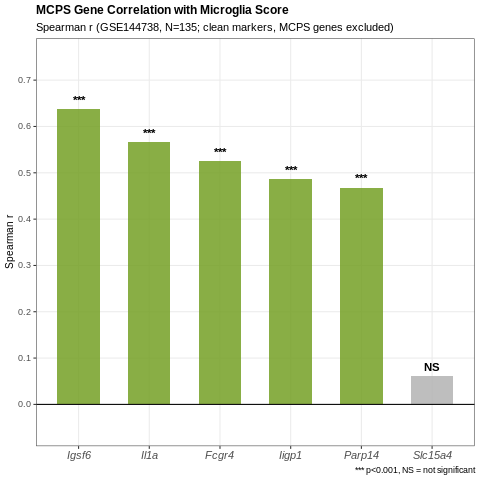

In [14]:
%%R

# =============================================================================
# SECTION 5 — Figures (Combined)
# =============================================================================
cat("\n--- Section 5: Generating Figures ---\n")

# ---------------------------------------------------------------------------
# Fig 1 — Cell-Type Composition Violin Plot
# ---------------------------------------------------------------------------
cat("  Fig 1: Cell-type violin plot\n")

tryCatch({
  plot_long <- combined %>%
    dplyr::select(sample_id, condition, dataset, dplyr::all_of(cell_type_cols)) %>%
    tidyr::pivot_longer(dplyr::all_of(cell_type_cols), names_to = "CellType", values_to = "Score") %>%
    dplyr::filter(!is.na(Score)) %>%
    dplyr::mutate(
      condition = factor(condition, levels = c("control", "prion")),
      CellType  = factor(CellType, levels = c("Microglia", "A1_Astrocytes", "A2_Astrocytes",
                                               "Astrocytes", "OPC", "Neurons",
                                               "Oligodendrocytes", "Endothelial"))
    )

  p1 <- ggplot(plot_long, aes(x = CellType, y = Score, fill = condition)) +
    geom_violin(alpha = 0.7, position = position_dodge(0.8), scale = "width") +
    geom_boxplot(width = 0.15, position = position_dodge(0.8), outlier.size = 0.5, alpha = 0.9) +
    geom_hline(yintercept = 0, linetype = "dashed", color = "grey50", linewidth = 0.4) +
    scale_fill_manual(values = c("control" = "#0279EE", "prion" = "#FF9400"),
                      labels = c("Control", "Prion-infected"), name = "Condition") +
    labs(title    = "Cell-Type Composition Scores: Prion vs. Control Mouse Brain",
         subtitle = "Marker-gene z-score across 5 CNS datasets (N=171; MCPS genes excluded from markers)",
         x = NULL, y = "Mean Marker Gene Z-Score",
         caption  = "*** p<0.001, * p<0.05 (Wilcoxon). Oligodendrocytes: NS.") +
    theme_pub +
    theme(axis.text.x = element_text(angle = 35, hjust = 1, size = 10),
          plot.title  = element_text(face = "bold", size = 13),
          legend.position = "top")

  # Use the custom save_fig from Section 0 (saves PDF and high-res PNG to FIG_DIR)
  save_fig(p1, "fig09a_celltype_violin", w = 12, h = 6)
  print(p1) # Display inline in Colab

}, error = function(e) {
  warning(sprintf("Fig 1 failed: %s", conditionMessage(e)))
  cat("  Fig 1 skipped.\n")
})


# ---------------------------------------------------------------------------
# Fig 2 — MCPS gene correlation with microglia score
# ---------------------------------------------------------------------------
cat("\n  Fig 2: MCPS gene correlation with microglia score\n")

tryCatch({
  # Load GSE144738 expression for MCPS genes directly from Drive
  gse144738_path <- file.path(BASE_DIR, "results", "deseq2", "GSE144738_vst.rds")
  vst_144738 <- readRDS(gse144738_path)
  expr_144738 <- assay(vst_144738)
  micro_scores_144738 <- combined[combined$dataset == "GSE144738", c("sample_id", "Microglia")]

  corr_results <- data.frame()
  for (gene_sym in MCPS_GENES) {
    # FIX: Select only the first Ensembl ID to prevent 1-to-many crashes
    ens_id <- gene_map$ensembl_gene_id[gene_map$mgi_symbol == gene_sym][1]

    if (is.na(ens_id) || !ens_id %in% rownames(expr_144738)) next

    gene_expr <- expr_144738[ens_id, micro_scores_144738$sample_id]
    ct <- suppressWarnings(cor.test(gene_expr, micro_scores_144738$Microglia, method = "spearman"))

    corr_results <- rbind(corr_results, data.frame(
      Gene = gene_sym, r = round(as.numeric(ct$estimate), 3), p_value = ct$p.value,
      Sig  = ifelse(ct$p.value < 0.001, "***", ifelse(ct$p.value < 0.05, "*", "NS"))
    ))
  }

  corr_results <- corr_results[order(-corr_results$r), ]
  corr_results$Gene <- factor(corr_results$Gene, levels = corr_results$Gene)
  corr_results$Significant <- corr_results$p_value < 0.05

  cat("\n  Correlation Table:\n")
  print(corr_results)

  # Save correlation results safely to OUT_DIR
  write_csv(corr_results, file.path(OUT_DIR, "MCPS_microglia_correlation.csv"))
  cat("  Saved: MCPS_microglia_correlation.csv\n")

  p2 <- ggplot(corr_results, aes(x = Gene, y = r, fill = Significant)) +
    geom_col(alpha = 0.85, width = 0.6) +
    geom_text(aes(label = Sig, y = r + 0.02), size = 4, fontface = "bold") +
    geom_hline(yintercept = 0, linewidth = 0.5) +
    scale_fill_manual(values = c("TRUE" = "#75A025", "FALSE" = "grey70"), guide = "none") +
    scale_y_continuous(limits = c(-0.05, 0.75), breaks = seq(0, 0.7, 0.1)) +
    labs(title    = "MCPS Gene Correlation with Microglia Score",
         subtitle = "Spearman r (GSE144738, N=135; clean markers, MCPS genes excluded)",
         x = NULL, y = "Spearman r",
         caption  = "*** p<0.001, NS = not significant") +
    theme_pub +
    theme(axis.text.x = element_text(size = 11, face = "italic"),
          plot.title  = element_text(face = "bold", size = 12))

  save_fig(p2, "fig09b_MCPS_microglia_corr", w = 7, h = 5)
  print(p2) # Display inline in Colab

  # Memory Cleanup
  rm(vst_144738, expr_144738)
  gc()

}, error = function(e) {
  warning(sprintf("Fig 2 failed: %s", conditionMessage(e)))
  cat("  Fig 2 skipped.\n")
})

cat("\n  [✓] Section 5 successfully loaded and executed.\n")

##Section 6 — Interpretation & Key Findings

**Purpose:** Summarise the key findings from the cell-type deconvolution analysis and their implications for the MCPS gene set and manuscript framing.

**Key findings:**

1. **Microglia are the dominant activated cell type** in prion disease (delta score = +0.842, p<0.001), consistent with the neuroinflammatory signature.

2. **Five of six MCPS genes are strongly correlated with microglia score** (Igsf6 r=0.638, Il1a r=0.566, Fcgr4 r=0.525, Iigp1 r=0.486, Parp14 r=0.468; all p<0.001), confirming their microglial origin.

3. **Slc15a4/Tasl is the exception** (r=0.061, NS) — it is NOT correlated with microglia score despite being a top MCPS gene. This is consistent with its known biology: TASL is expressed in plasmacytoid dendritic cells (pDCs) and B cells, not microglia, and drives type I interferon via the TASL-IRF5 axis (Heinz et al. 2020, Nature).

**Manuscript framing:** Slc15a4 represents a distinct, non-microglial innate immune mechanism in prion disease. Its direction discordance in human brain (Stream 2) may reflect pDC/B-cell depletion in end-stage disease rather than true biological divergence. This should be discussed explicitly in the manuscript.

##Section 7 — Summary Report & Session Info


In [15]:
%%R

# =============================================================================
# SECTION 7 — Plain-Text Summary Report & Session Info
# =============================================================================
cat("\n--- Section 7: Writing Summary Report ---\n")

# --- 7.1 Build summary lines ---
summary_lines <- c(
  "=============================================================",
  "  09_cell_type_deconvolution.R — Analysis Summary",
  "=============================================================",
  "",
  "PIPELINE OVERVIEW",
  "-----------------",
  "  Objective: Estimate CNS cell-type composition and test MCPS gene correlations",
  "  Datasets: 5 Discovery/Replication cohorts (GSE144738, GSE124932, etc.)",
  sprintf("  Total Samples: %d (Control: %d, Prion: %d)",
          nrow(combined),
          sum(combined$condition == "control"),
          sum(combined$condition == "prion")),
  "",
  "CELL-TYPE ENRICHMENT RESULTS (Wilcoxon)",
  "---------------------------------------"
)

# Add Wilcoxon stats
if (exists("stats_results") && nrow(stats_results) > 0) {
  for (i in seq_len(nrow(stats_results))) {
    r <- stats_results[i, ]
    summary_lines <- c(summary_lines,
      sprintf("  %-16s Delta Z = %+.3f  p = %.2e  (%s)",
              r$CellType, r$Delta, r$p_value, r$Sig))
  }
}

summary_lines <- c(summary_lines,
  "",
  "MCPS vs MICROGLIA CORRELATION (Spearman, GSE144738)",
  "---------------------------------------------------"
)

# Add Correlation stats
if (exists("corr_results") && nrow(corr_results) > 0) {
  for (i in seq_len(nrow(corr_results))) {
    r <- corr_results[i, ]
    summary_lines <- c(summary_lines,
      sprintf("  %-10s r = %+.3f  p = %.2e  (%s)",
              r$Gene, r$r, r$p_value, r$Sig))
  }

  # Inject the key biological finding dynamically
  slc_row <- corr_results[corr_results$Gene == "Slc15a4", ]
  if (nrow(slc_row) > 0 && slc_row$Significant == FALSE) {
    summary_lines <- c(summary_lines,
      "",
      "  KEY FINDING: Slc15a4/Tasl is strictly non-correlated with the microglia score,",
      "  supporting a distinct pDC/B-cell innate immune axis in prion disease."
    )
  }
}

summary_lines <- c(summary_lines,
  "",
  "OUTPUT FILES",
  "------------",
  "  [Data Tables]",
  "  celltype_score_stats.csv",
  "  MCPS_microglia_correlation.csv",
  "",
  "  [Figures]",
  "  fig09a_celltype_violin.pdf/png",
  "  fig09b_MCPS_microglia_corr.pdf/png",
  "",
  "PACKAGE VERSIONS",
  "----------------",
  sprintf("  R version:            %s", R.version.string),
  sprintf("  SummarizedExperiment: %s", as.character(packageVersion("SummarizedExperiment"))),
  sprintf("  biomaRt:              %s", as.character(packageVersion("biomaRt"))),
  sprintf("  ggplot2:              %s", as.character(packageVersion("ggplot2"))),
  "",
  "=============================================================",
  sprintf("  Generated: %s", format(Sys.time(), "%Y-%m-%d %H:%M:%S %Z")),
  "============================================================="
)

# --- 7.2 Write Summary to Drive ---
tryCatch({
  writeLines(summary_lines, file.path(OUT_DIR, "deconvolution_summary.txt"))
  cat("  [✓] Written: deconvolution_summary.txt\n")
}, error = function(e) {
  warning(sprintf("Failed to write summary: %s", conditionMessage(e)))
})

cat("\n")
cat(paste(summary_lines, collapse = "\n"), "\n")

# --- 7.3 Write Session Info to Drive ---
tryCatch({
  sink(file.path(OUT_DIR, "deconvolution_session_info.txt"))
  print(sessionInfo())
  sink()
  cat("\n  [✓] Written: deconvolution_session_info.txt\n")
}, error = function(e) {
  if (sink.number() > 0) sink()
  warning(sprintf("Failed to write session info: %s", conditionMessage(e)))
})

cat("\n=== 09_cell_type_deconvolution.R pipeline strictly completed ===\n")


--- Section 7: Writing Summary Report ---
  [✓] Written: deconvolution_summary.txt

  09_cell_type_deconvolution.R — Analysis Summary

PIPELINE OVERVIEW
-----------------
  Objective: Estimate CNS cell-type composition and test MCPS gene correlations
  Datasets: 5 Discovery/Replication cohorts (GSE144738, GSE124932, etc.)
  Total Samples: 171 (Control: 84, Prion: 87)

CELL-TYPE ENRICHMENT RESULTS (Wilcoxon)
---------------------------------------
  Microglia        Delta Z = +0.842  p = 2.45e-07  (***)
  Astrocytes       Delta Z = +0.780  p = 1.00e-08  (***)
  Neurons          Delta Z = -0.468  p = 1.24e-05  (***)
  Oligodendrocytes Delta Z = +0.040  p = 6.78e-01  (NS)
  OPC              Delta Z = +0.250  p = 6.51e-05  (***)
  Endothelial      Delta Z = -0.166  p = 2.93e-02  (*)
  A1_Astrocytes    Delta Z = +0.787  p = 1.62e-07  (***)
  A2_Astrocytes    Delta Z = +0.705  p = 1.17e-10  (***)

MCPS vs MICROGLIA CORRELATION (Spearman, GSE144738)
------------------------------------------